# Data Visualization — Week 1 Assignments

**Name:** kamran khan 
**Roll No:** BSDS030
**Course:** Data Visualization (Week 1)



In [1]:
# Imports and plotting setup
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("/mnt/data")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 180
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Load all five datasets
datasaurus = pd.read_csv(DATA_DIR / "datasaurus.csv")
flights = pd.read_csv(DATA_DIR / "flights.csv")
gapminder = pd.read_csv(DATA_DIR / "gapminder.csv")
mpg = pd.read_csv(DATA_DIR / "mpg.csv")
penguins = pd.read_csv(DATA_DIR / "penguins.csv")

print("Datasets loaded:")
for name, df in {
    "datasaurus": datasaurus,
    "flights": flights,
    "gapminder": gapminder,
    "mpg": mpg,
    "penguins": penguins,
}.items():
    print(f"{name:12s}: {df.shape[0]:4d} rows × {df.shape[1]} columns")


Datasets loaded:
datasaurus  : 1846 rows × 3 columns
flights     :  144 rows × 3 columns
gapminder   : 1704 rows × 6 columns
mpg         :  398 rows × 9 columns
penguins    :  344 rows × 7 columns


## Task 1 — Prove why we visualize

The Datasaurus dataset contains 13 groups with 142 points in each group. The first step is to calculate the same summary statistics for every group before looking at the points.


In [2]:
# Task 1.1 — Summary statistics for all 13 datasets
datasaurus_summary = (
    datasaurus.groupby("dataset")
    .agg(
        mean_x=("x", "mean"),
        mean_y=("y", "mean"),
        sd_x=("x", "std"),
        sd_y=("y", "std"),
    )
)

datasaurus_summary["correlation"] = (
    datasaurus.groupby("dataset")
    .apply(lambda g: g["x"].corr(g["y"]))
)

datasaurus_summary = datasaurus_summary.reset_index().sort_values("dataset")
datasaurus_summary.round(3)


,dataset,mean_x,mean_y,sd_x,sd_y,correlation
0,away,54.266,47.835,16.770,26.940,-0.064
1,bullseye,54.269,47.831,16.769,26.936,-0.069
2,circle,54.267,47.838,16.760,26.930,-0.068
3,dino,54.263,47.832,16.765,26.935,-0.064
4,dots,54.260,47.840,16.768,26.930,-0.060
5,h_lines,54.261,47.830,16.766,26.940,-0.062
6,high_lines,54.269,47.835,16.767,26.940,-0.069
7,slant_down,54.268,47.836,16.767,26.936,-0.069
8,slant_up,54.266,47.831,16.769,26.939,-0.069
9,star,54.267,47.840,16.769,26.930,-0.063


### What the table alone would suggest

If this table were all I had, I would conclude that the 13 datasets are almost interchangeable. Their means, standard deviations, and correlations are extremely close, so I would expect their scatter plots to have roughly the same shape and direction.

That conclusion would be misleading. The statistics describe only a few numerical summaries; they do not describe the actual geometry of the points.


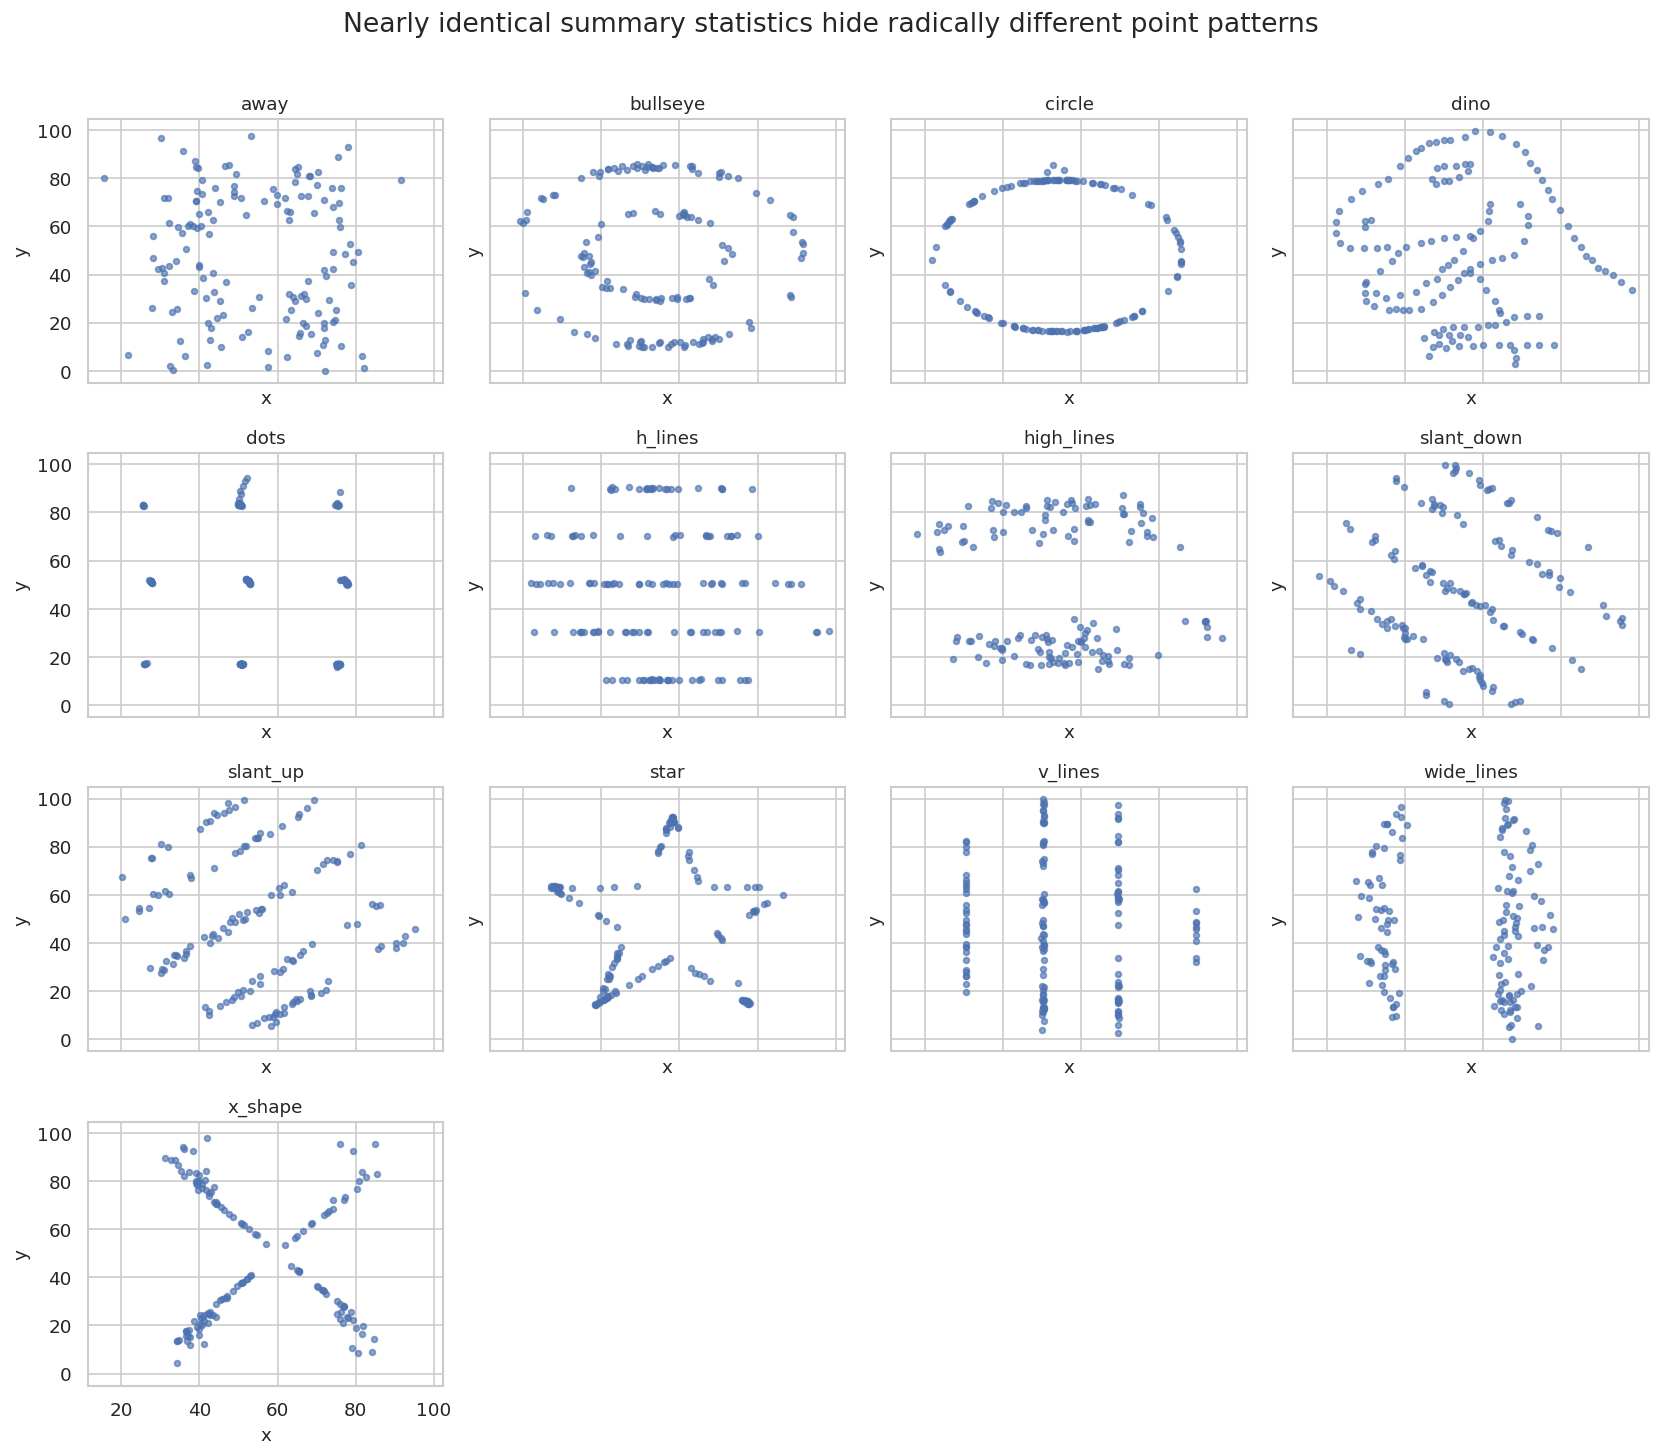

In [3]:
# Task 1.3 — All 13 scatter plots
fig, axes = plt.subplots(4, 4, figsize=(14, 12), sharex=True, sharey=True)
axes = axes.ravel()

for ax, (name, group) in zip(axes, datasaurus.groupby("dataset")):
    ax.scatter(group["x"], group["y"], s=12, alpha=0.65)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("x")
    ax.set_ylabel("y")

for ax in axes[len(datasaurus["dataset"].unique()):]:
    ax.axis("off")

fig.suptitle(
    "Nearly identical summary statistics hide radically different point patterns",
    fontsize=16,
    y=1.01,
)
plt.tight_layout()
plt.show()


**Why this chart?** A grid of scatter plots is the right choice because the question is about the shape and arrangement of individual observations, not just averages and correlations.

**What I found:** the 13 datasets produce very different structures—curves, clusters, lines, rings, and other shapes—even though their summary statistics are almost identical. Having 142 observations instead of 11 does not make the summaries sufficient. More observations improve estimates within a dataset, but they still cannot reveal structure that is discarded when the data are reduced to a few statistics.

**Rows/outliers excluded:** none. All 1,846 rows were plotted.


## Task 2 — Trends and the spaghetti problem

The Gapminder data contain 142 countries measured every five years from 1952 to 2007. The dataset has no missing values.


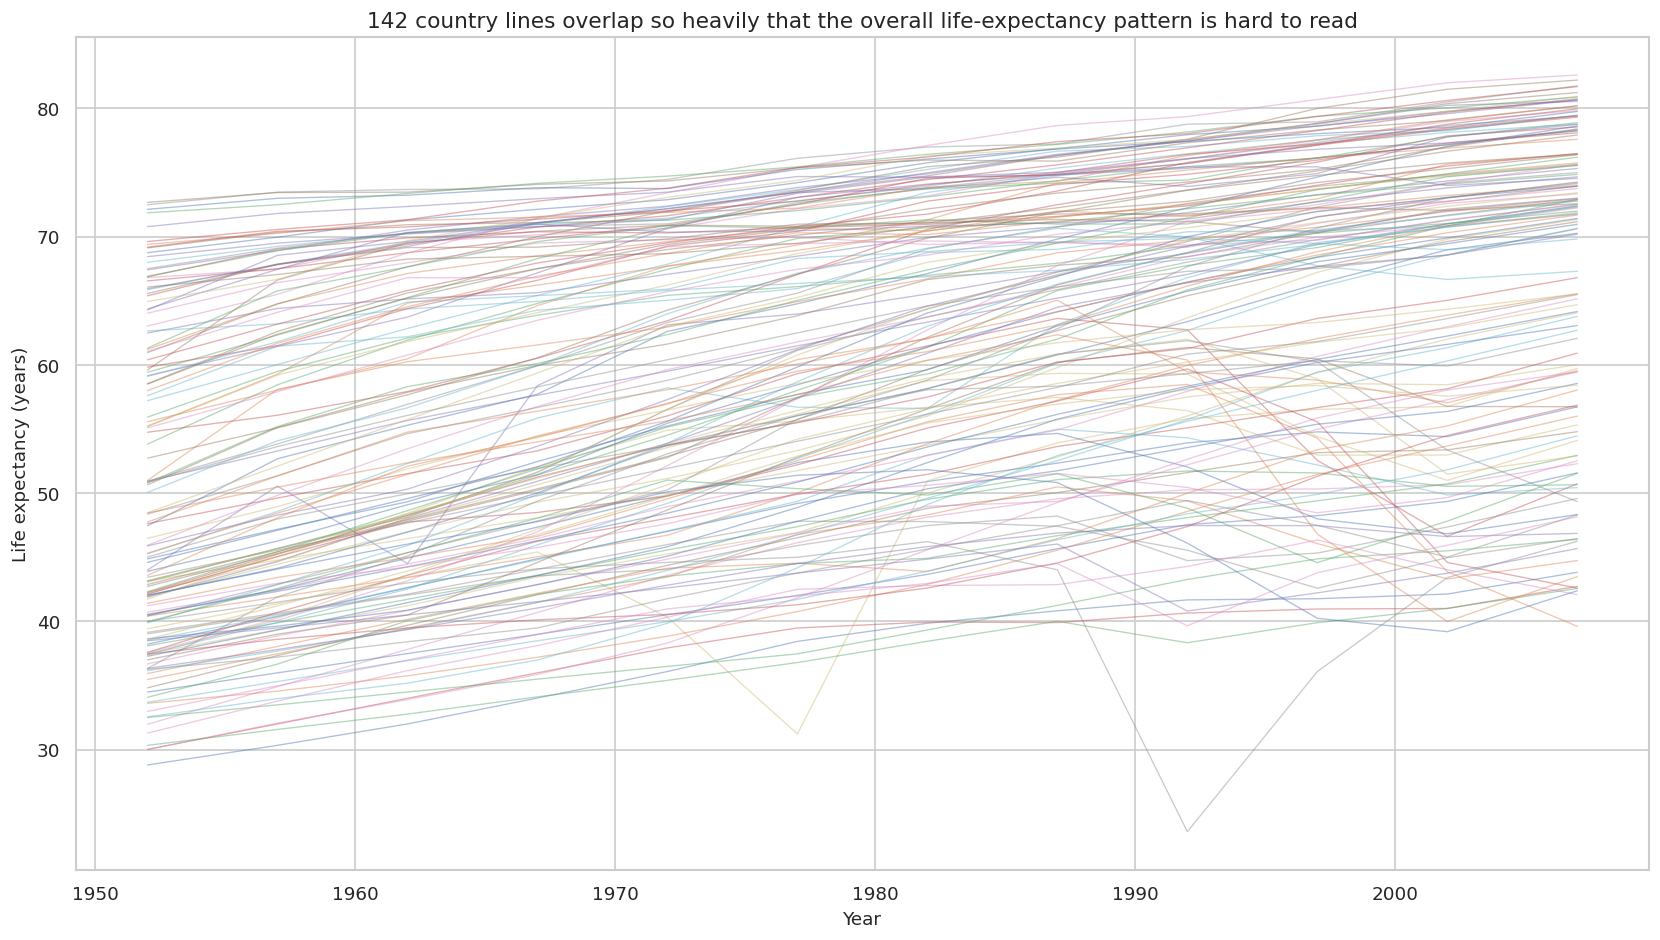

In [4]:
# Task 2.1 — Deliberately messy country-level line chart
fig, ax = plt.subplots(figsize=(14, 8))

for country, group in gapminder.groupby("country"):
    ax.plot(group["year"], group["lifeExp"], linewidth=0.8, alpha=0.45)

ax.set_title("142 country lines overlap so heavily that the overall life-expectancy pattern is hard to read")
ax.set_xlabel("Year")
ax.set_ylabel("Life expectancy (years)")
plt.tight_layout()
plt.show()


**Why this chart?** A line chart is appropriate for change over time, but drawing one line for every country creates the classic spaghetti problem.

**What is wrong with it?** There are 142 lines, so crossings and overlaps dominate the figure. A legend would also be far too long to be useful. The chart contains the information, but it makes the reader work too hard to find a pattern.

**Rows/outliers excluded:** none. All 1,704 rows are included.


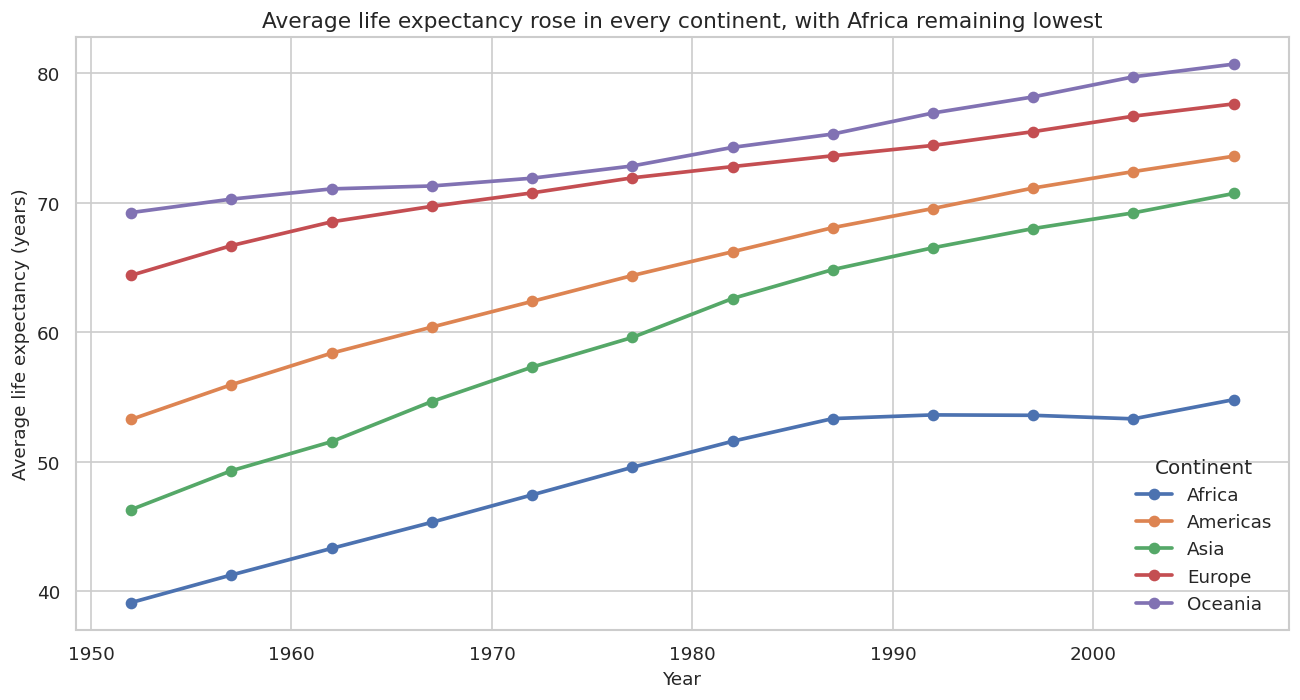

In [5]:
# Task 2.2(a) — Aggregate to one line per continent
continent_life = (
    gapminder.groupby(["continent", "year"], as_index=False)["lifeExp"]
    .mean()
)

fig, ax = plt.subplots(figsize=(11, 6))
for continent, group in continent_life.groupby("continent"):
    ax.plot(group["year"], group["lifeExp"], marker="o", linewidth=2.2, label=continent)

ax.set_title("Average life expectancy rose in every continent, with Africa remaining lowest")
ax.set_xlabel("Year")
ax.set_ylabel("Average life expectancy (years)")
ax.legend(title="Continent", frameon=False)
plt.tight_layout()
plt.show()


**Why this chart?** Aggregating to continents reduces 142 lines to five meaningful lines while preserving the broad regional trend.

**What I found:** average life expectancy increased across all continents. Africa remained the lowest on average, while Europe and Oceania stayed among the highest. This version is much easier to compare than the country-level spaghetti chart.

**Rows/outliers excluded:** none; aggregation uses all 1,704 observations.


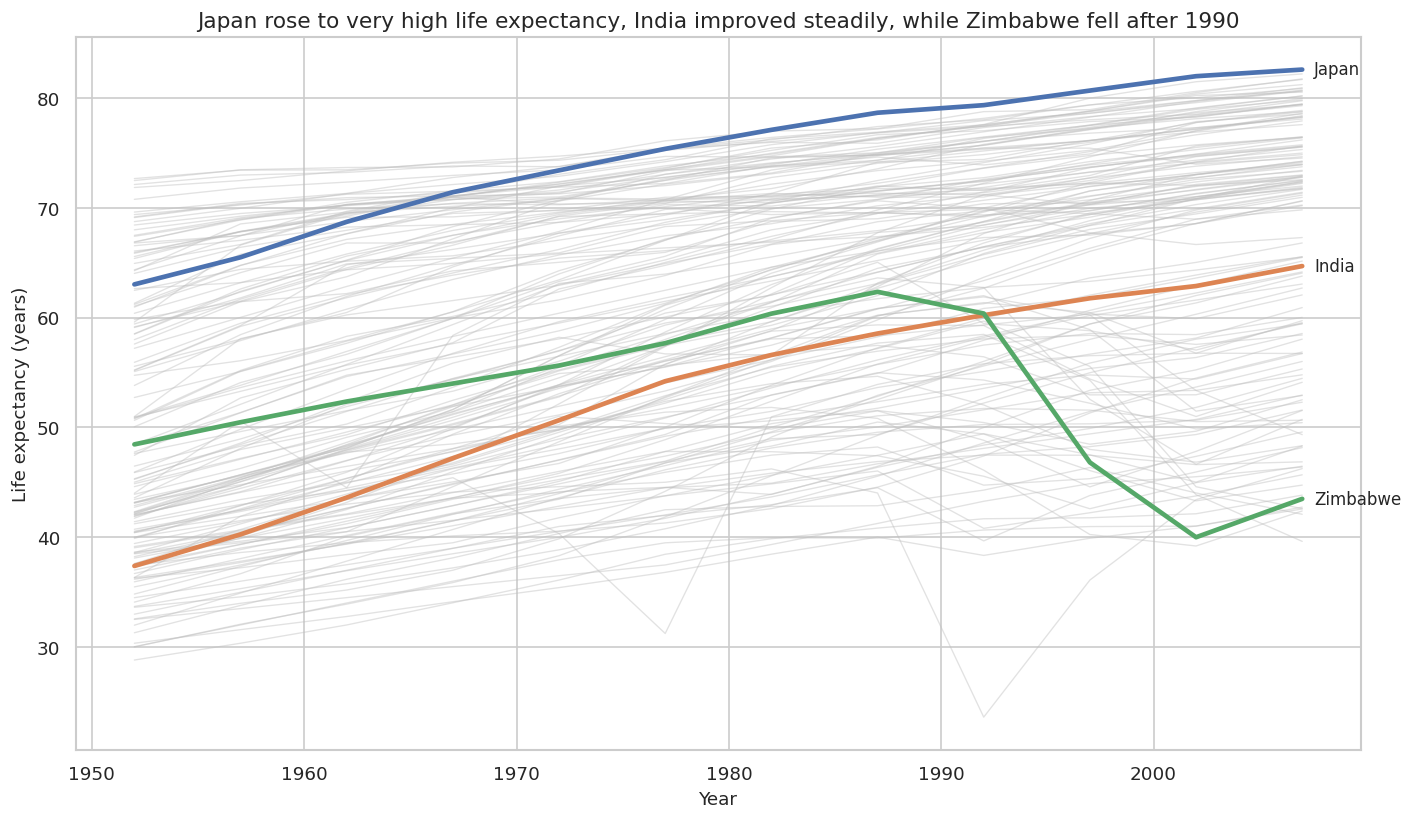

In [6]:
# Task 2.2(b) — Highlight three countries
highlight = {
    "Japan": "highlight",
    "India": "highlight",
    "Zimbabwe": "highlight",
}

fig, ax = plt.subplots(figsize=(12, 7))

for country, group in gapminder.groupby("country"):
    if country not in highlight:
        ax.plot(group["year"], group["lifeExp"], color="0.75", linewidth=0.8, alpha=0.45)

highlight_styles = {
    "Japan": {"linewidth": 2.8},
    "India": {"linewidth": 2.8},
    "Zimbabwe": {"linewidth": 2.8},
}

for country, style in highlight_styles.items():
    group = gapminder[gapminder["country"] == country]
    ax.plot(group["year"], group["lifeExp"], linewidth=style["linewidth"], label=country)

    last = group.iloc[-1]
    ax.annotate(
        country,
        xy=(last["year"], last["lifeExp"]),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
    )

ax.set_title("Japan rose to very high life expectancy, India improved steadily, while Zimbabwe fell after 1990")
ax.set_xlabel("Year")
ax.set_ylabel("Life expectancy (years)")
plt.tight_layout()
plt.show()


**Why this chart?** Highlighting keeps the full context but directs attention to three deliberately different trajectories. Direct labels are clearer than a 142-entry legend.

**What I found:** Japan shows a strong rise to one of the highest life expectancies, India shows steady improvement, and Zimbabwe has a very different path with a major decline in the later period. These individual stories disappear in the continent averages.

**Rows/outliers excluded:** none. All country lines remain in the background; only three are emphasized.


**Why this chart?** The question asks whether the distance between the richest and poorest countries narrowed over time, so a line chart of the richest-to-poorest ratio gives one direct measure of that gap.

**What I found:** the ratio fell from about 363 times in 1952 to about 178 times in 2007, so the gap narrowed overall. It was not a smooth decline: the ratio widened again in some periods. This is more informative than using the raw GDP-per-capita difference because the underlying values are strongly skewed.

**Rows/outliers excluded:** none.


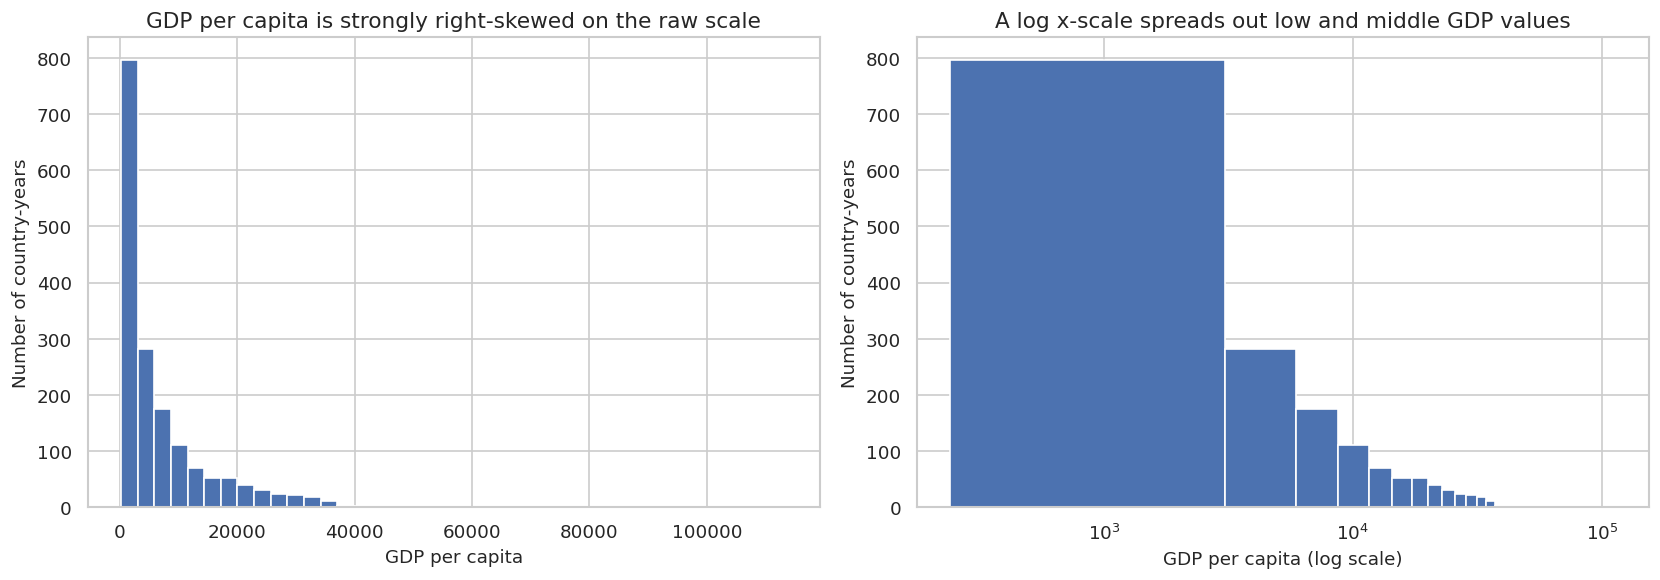

In [8]:
# Task 2.5 — GDP-per-capita distribution on raw and log x-scales
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(gapminder["gdpPercap"], bins=40)
axes[0].set_title("GDP per capita is strongly right-skewed on the raw scale")
axes[0].set_xlabel("GDP per capita")
axes[0].set_ylabel("Number of country-years")

axes[1].hist(gapminder["gdpPercap"], bins=40)
axes[1].set_xscale("log")
axes[1].set_title("A log x-scale spreads out low and middle GDP values")
axes[1].set_xlabel("GDP per capita (log scale)")
axes[1].set_ylabel("Number of country-years")

plt.tight_layout()
plt.show()


**Why this chart?** Histograms show the shape of a distribution, and placing the raw and log-scaled versions side by side makes the effect of the transformation easy to judge.

**What I found:** GDP per capita is heavily right-skewed on the raw scale because a relatively small number of country-years have very high values. The log scale spreads the low and middle values apart, making the distribution easier to inspect. For the gap chart above, I therefore used a ratio rather than letting a few extreme GDP values dominate a raw-scale comparison.

**Rows/outliers excluded:** none; the log transformation changes the axis scale, not the observations.


## Task 3 — Distributions and relationships

The penguins data contain 344 rows. Two penguins have all four measurement fields missing, and 11 rows have missing sex. I keep the rows in the dataset but exclude them only from charts where the missing field is required.


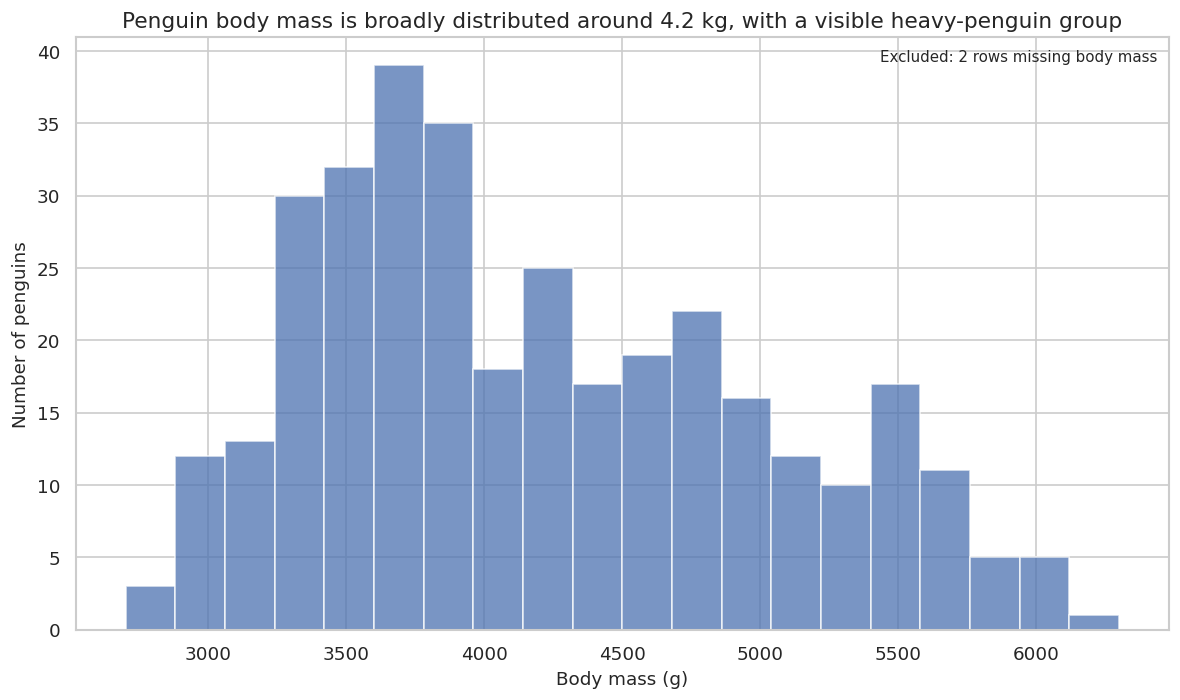

In [9]:
# Task 3.1 — Overall body-mass distribution
mass = penguins.dropna(subset=["body_mass_g"])

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(mass["body_mass_g"], bins=20, density=False, alpha=0.75)
ax.set_title("Penguin body mass is broadly distributed around 4.2 kg, with a visible heavy-penguin group")
ax.set_xlabel("Body mass (g)")
ax.set_ylabel("Number of penguins")
ax.text(0.99, 0.98, "Excluded: 2 rows missing body mass",
        transform=ax.transAxes, ha="right", va="top", fontsize=9)
plt.tight_layout()
plt.show()


**Why this chart?** A histogram is appropriate for showing the shape of one numerical distribution. It lets us see whether body mass is concentrated in one hump or separated into groups.

**What I found:** the overall distribution is not a simple single symmetric hump. The heavier penguins create a second concentration, suggesting that species may be responsible for much of the shape.

**Missing-value decision:** the 2 rows with missing body mass were excluded from this chart. No other rows were excluded.


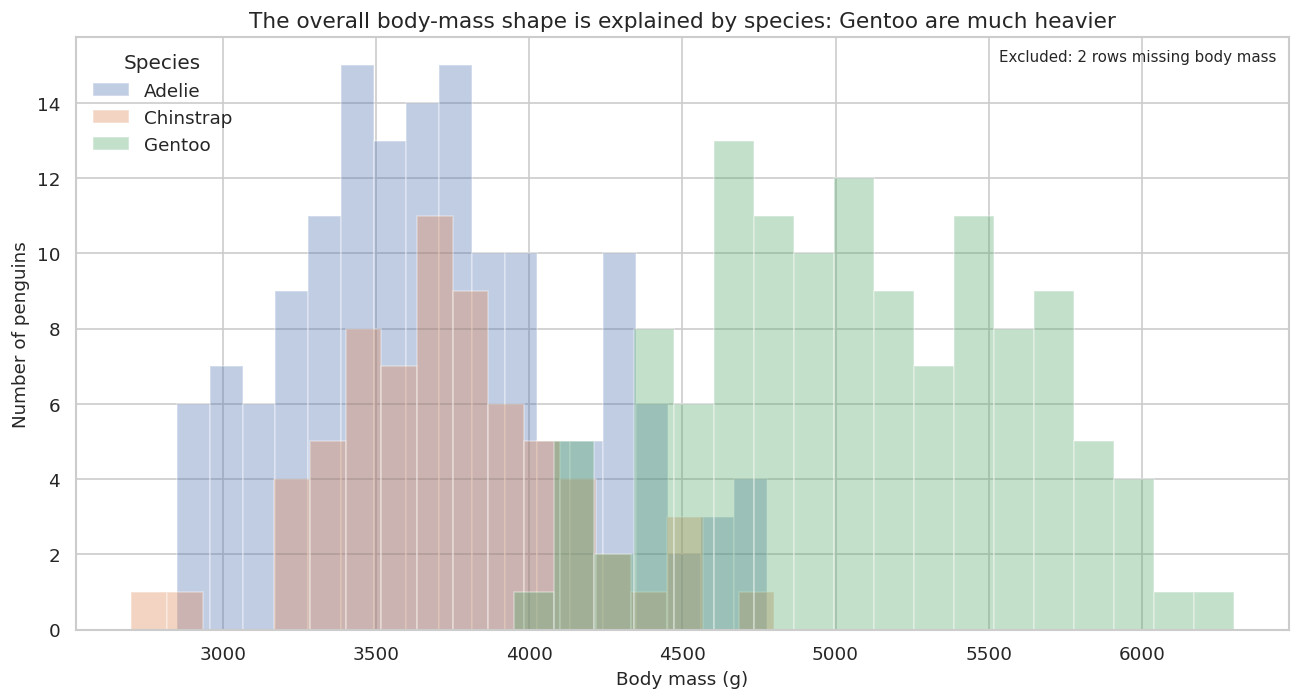

In [10]:
# Task 3.2 — Body-mass distribution split by species
fig, ax = plt.subplots(figsize=(11, 6))
species_order = ["Adelie", "Chinstrap", "Gentoo"]

for species in species_order:
    vals = mass.loc[mass["species"] == species, "body_mass_g"]
    ax.hist(vals, bins=18, alpha=0.35, label=species)

ax.set_title("The overall body-mass shape is explained by species: Gentoo are much heavier")
ax.set_xlabel("Body mass (g)")
ax.set_ylabel("Number of penguins")
ax.legend(title="Species", frameon=False)
ax.text(0.99, 0.98, "Excluded: 2 rows missing body mass",
        transform=ax.transAxes, ha="right", va="top", fontsize=9)
plt.tight_layout()
plt.show()


**Why this chart?** Splitting the distribution by species tests whether the multiple-looking shape in the overall histogram comes from mixing distinct groups.

**What I found:** yes. Adelie and Chinstrap have similar, lighter body-mass distributions, while Gentoo are clearly heavier. The group structure explains much of the shape seen in the overall histogram.

**Missing-value decision:** the same 2 rows missing body mass were excluded.


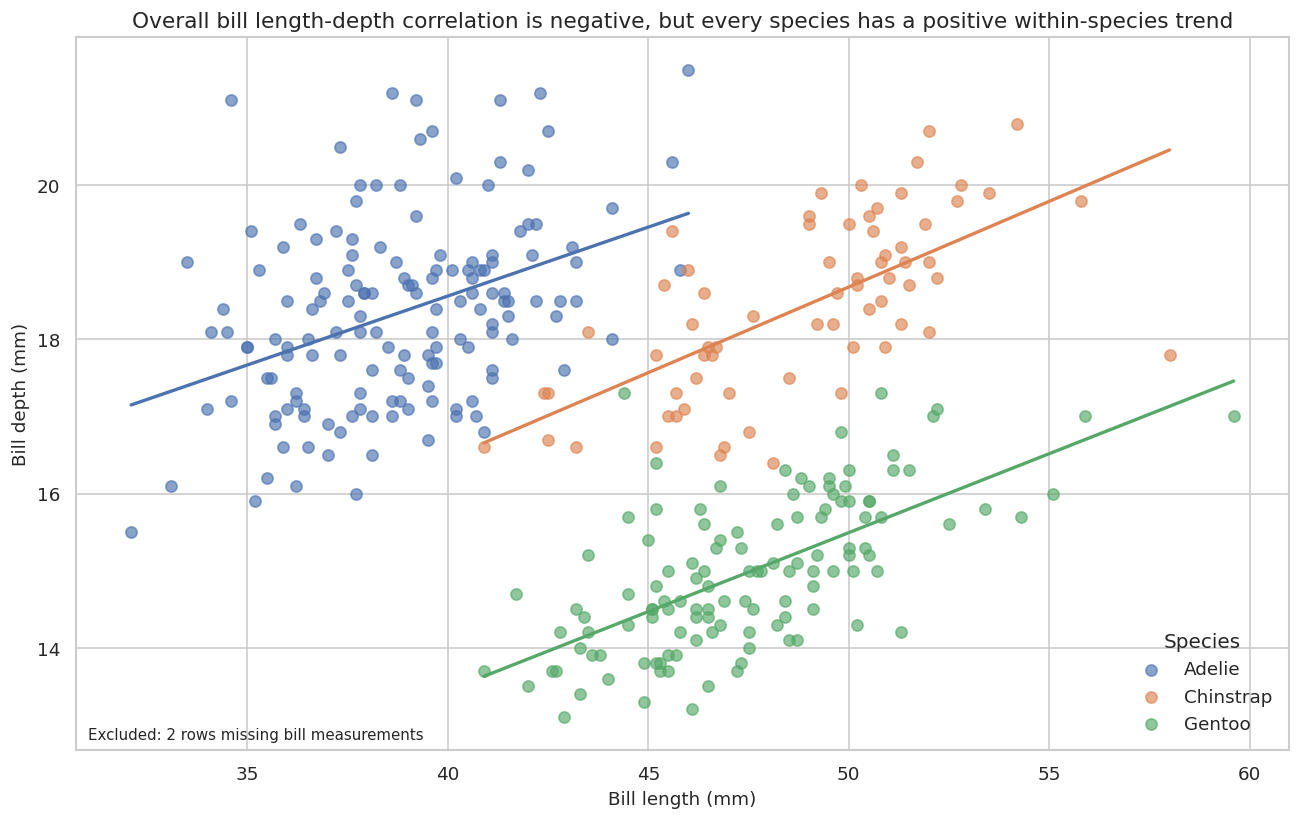

Overall correlation: -0.235
Within-species correlations:
species
Adelie       0.391
Chinstrap    0.654
Gentoo       0.643
dtype: float64


In [11]:
# Task 3.3 — Bill length vs bill depth, with separate regression lines
bill = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm"])

fig, ax = plt.subplots(figsize=(11, 7))
species_order = ["Adelie", "Chinstrap", "Gentoo"]

for species in species_order:
    g = bill[bill["species"] == species]
    ax.scatter(g["bill_length_mm"], g["bill_depth_mm"], s=45, alpha=0.65, label=species)
    coef = np.polyfit(g["bill_length_mm"], g["bill_depth_mm"], 1)
    xline = np.linspace(g["bill_length_mm"].min(), g["bill_length_mm"].max(), 100)
    ax.plot(xline, coef[0] * xline + coef[1], linewidth=2)

ax.set_title("Overall bill length-depth correlation is negative, but every species has a positive within-species trend")
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
ax.legend(title="Species", frameon=False)
ax.text(0.01, 0.01, "Excluded: 2 rows missing bill measurements",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

overall_corr = bill["bill_length_mm"].corr(bill["bill_depth_mm"])
within_corr = bill.groupby("species").apply(
    lambda g: g["bill_length_mm"].corr(g["bill_depth_mm"])
).round(3)

print("Overall correlation:", round(overall_corr, 3))
print("Within-species correlations:")
print(within_corr)


**Why this chart?** A scatter plot is the natural choice for two continuous measurements because it shows both the overall relationship and the separation between species. Separate fitted lines make the within-species directions visible.

**What I found:** across all penguins, bill length and bill depth have a negative correlation (about −0.235). Within each species, the correlations are positive: about 0.391 for Adelie, 0.654 for Chinstrap, and 0.643 for Gentoo. The negative overall pattern is therefore caused by the species groups occupying different regions of the plot. This is an example of **Simpson's paradox**: an aggregate relationship can reverse when the groups are examined separately.

**Missing-value decision:** the 2 rows missing bill measurements were excluded.


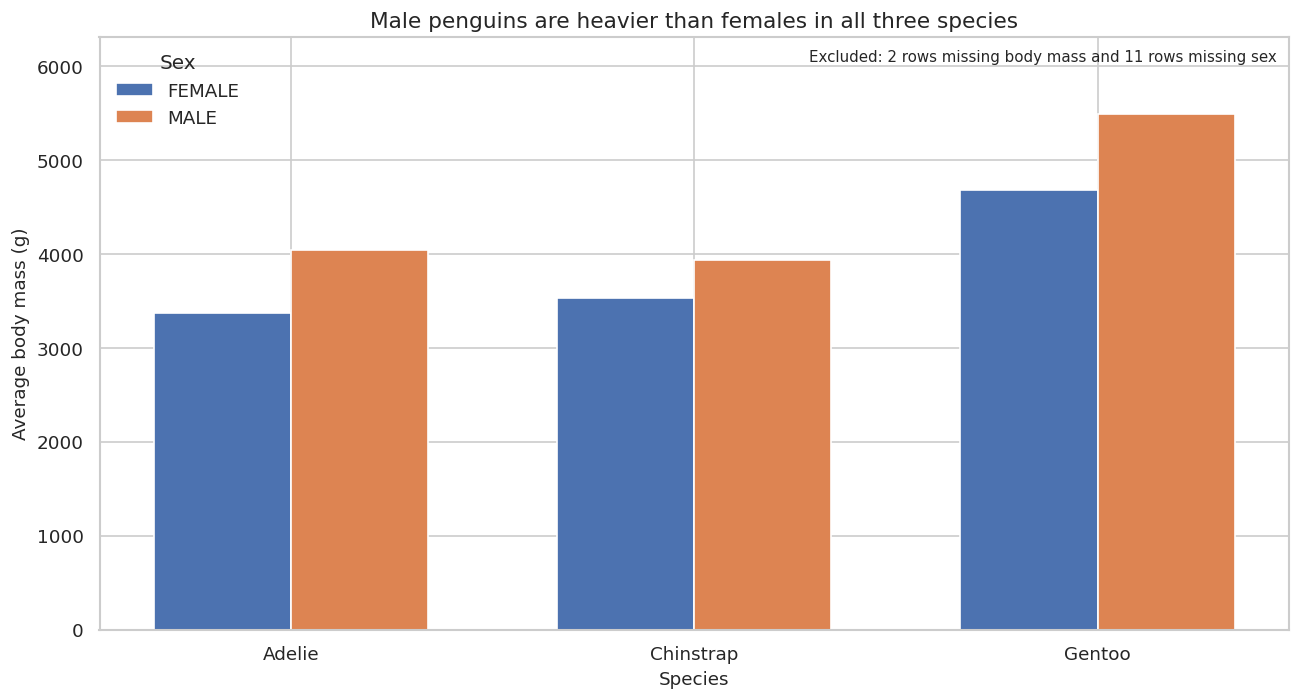

In [12]:
# Task 3.4 — Average body mass by species and sex
sex_mass = penguins.dropna(subset=["body_mass_g", "sex"])

mean_mass = sex_mass.groupby(["species", "sex"], as_index=False)["body_mass_g"].mean()
species_order = ["Adelie", "Chinstrap", "Gentoo"]
sex_order = ["FEMALE", "MALE"]

x = np.arange(len(species_order))
width = 0.34

fig, ax = plt.subplots(figsize=(11, 6))
for i, sex in enumerate(sex_order):
    vals = mean_mass.set_index(["species", "sex"]).reindex(
        pd.MultiIndex.from_product([species_order, [sex]])
    )["body_mass_g"].values
    offset = (-0.5 + i) * width
    bars = ax.bar(x + offset, vals, width, label=sex)

ax.set_title("Male penguins are heavier than females in all three species")
ax.set_xlabel("Species")
ax.set_ylabel("Average body mass (g)")
ax.set_xticks(x)
ax.set_xticklabels(species_order)
ax.set_ylim(0, mean_mass["body_mass_g"].max() * 1.15)
ax.text(0.99, 0.98, "Excluded: 2 rows missing body mass and 11 rows missing sex",
        transform=ax.transAxes, ha="right", va="top", fontsize=9)
ax.legend(title="Sex", frameon=False)
plt.tight_layout()
plt.show()


**Why this chart?** A grouped bar chart is useful here because the question is a direct comparison of group averages across two categorical variables. The y-axis starts at zero so the bar lengths are not visually exaggerated.

**What I found:** males have a higher average body mass than females for Adelie, Chinstrap, and Gentoo. Gentoo are also the heaviest species overall.

**Missing-value decision:** rows without usable body mass or sex were excluded. That removes 2 rows with missing body mass and 11 rows with missing sex.


## Task 4 — Pick the right chart, five times

The `mpg` dataset has 398 cars. Horsepower is missing for six cars, but those six rows can still be used for questions that do not require horsepower.


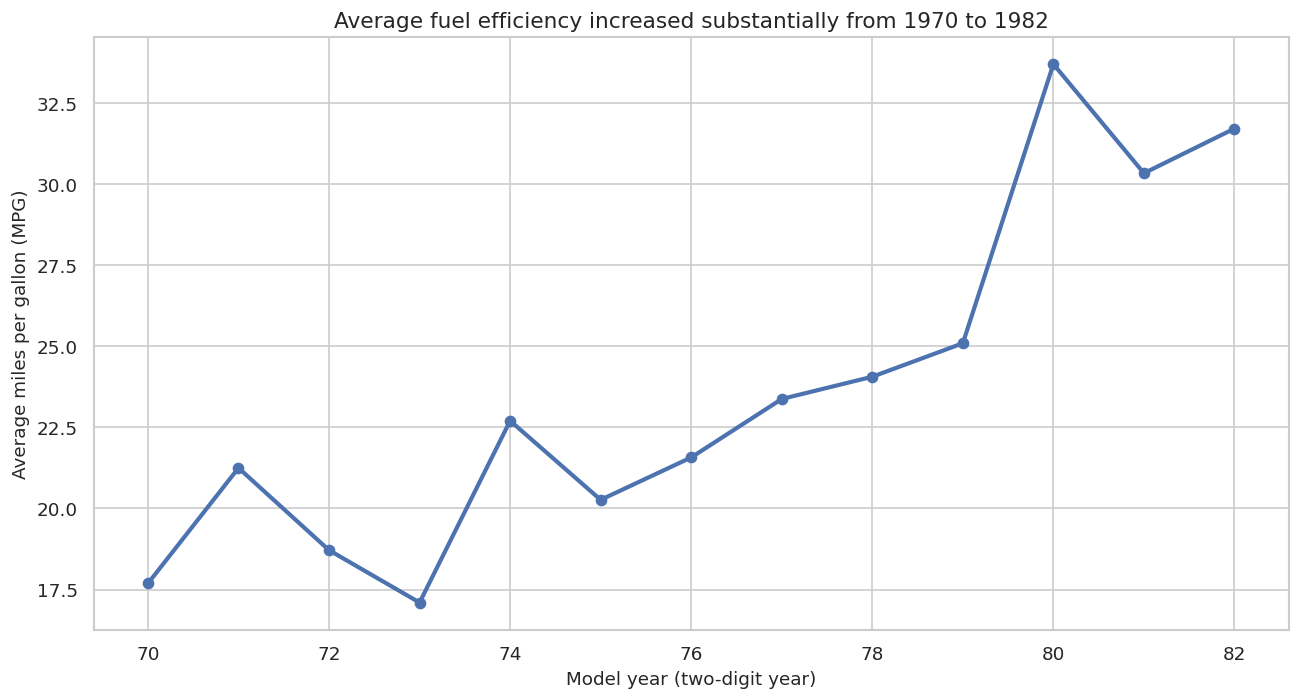

In [13]:
# Task 4.1 — Did cars become more fuel-efficient?
year_mpg = mpg.groupby("model_year", as_index=False)["mpg"].mean()

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(year_mpg["model_year"], year_mpg["mpg"], marker="o", linewidth=2.5)
ax.set_title("Average fuel efficiency increased substantially from 1970 to 1982")
ax.set_xlabel("Model year (two-digit year)")
ax.set_ylabel("Average miles per gallon (MPG)")
plt.tight_layout()
plt.show()


**Why this chart?** A line chart fits a time trend because the years have a natural order. It makes the overall direction easier to see than separate bars for every year.

**Finding:** average MPG increased substantially across the period, despite some year-to-year variation.

**Rows excluded:** none.


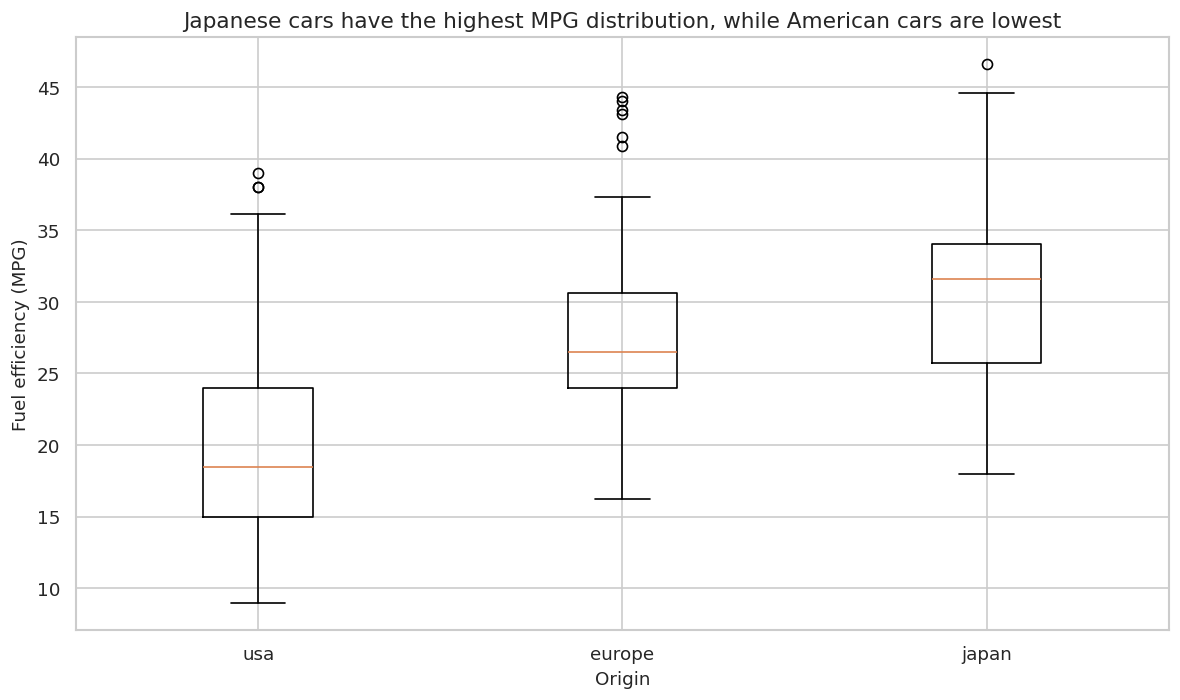

In [14]:
# Task 4.2 — Fuel efficiency by origin
origin_order = ["usa", "europe", "japan"]
groups = [mpg.loc[mpg["origin"] == o, "mpg"].values for o in origin_order]

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(groups, labels=origin_order, patch_artist=False)
ax.set_title("Japanese cars have the highest MPG distribution, while American cars are lowest")
ax.set_xlabel("Origin")
ax.set_ylabel("Fuel efficiency (MPG)")
plt.tight_layout()
plt.show()


**Why this chart?** A boxplot is better than a single mean because the question asks whether the groups differ in fuel efficiency, and the distribution and spread matter. The light point overlay shows the individual observations without turning the chart into a bar chart.

**Finding:** Japanese cars have the highest MPG distribution, European cars are in the middle, and American cars are lowest.

**Rows excluded:** none.


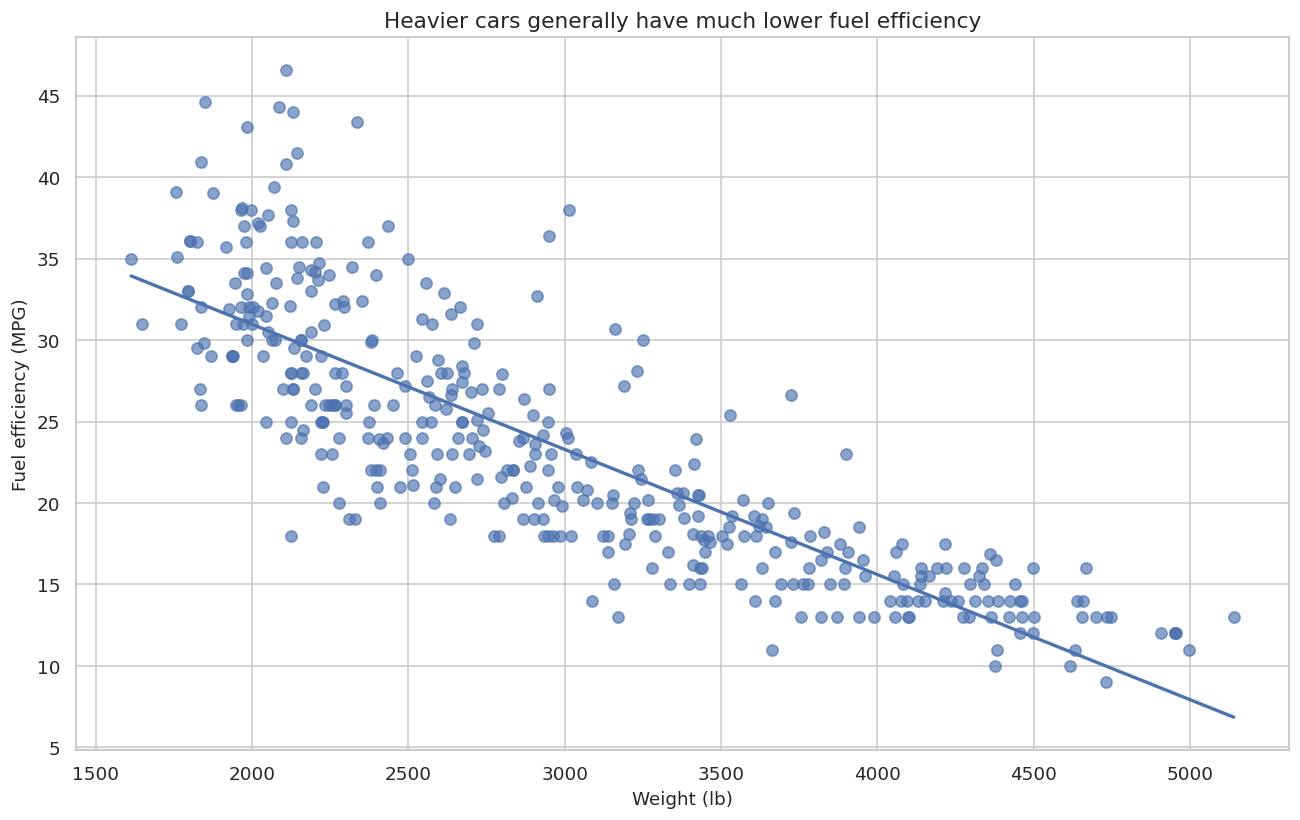

Weight–MPG correlation: -0.832


In [15]:
# Task 4.3 — Weight vs fuel efficiency
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(mpg["weight"], mpg["mpg"], alpha=0.65, s=45)
coef = np.polyfit(mpg["weight"], mpg["mpg"], 1)
xline = np.linspace(mpg["weight"].min(), mpg["weight"].max(), 100)
ax.plot(xline, coef[0] * xline + coef[1], linewidth=2)
ax.set_title("Heavier cars generally have much lower fuel efficiency")
ax.set_xlabel("Weight (lb)")
ax.set_ylabel("Fuel efficiency (MPG)")
plt.tight_layout()
plt.show()

print("Weight–MPG correlation:", round(mpg["weight"].corr(mpg["mpg"]), 3))


**Why this chart?** A scatter plot is the right chart for two continuous variables because it shows the strength, direction, and spread of their relationship.

**Finding:** weight and MPG have a strong negative relationship (correlation about −0.832). Heavier cars generally use more fuel per mile.

**Rows excluded:** none.


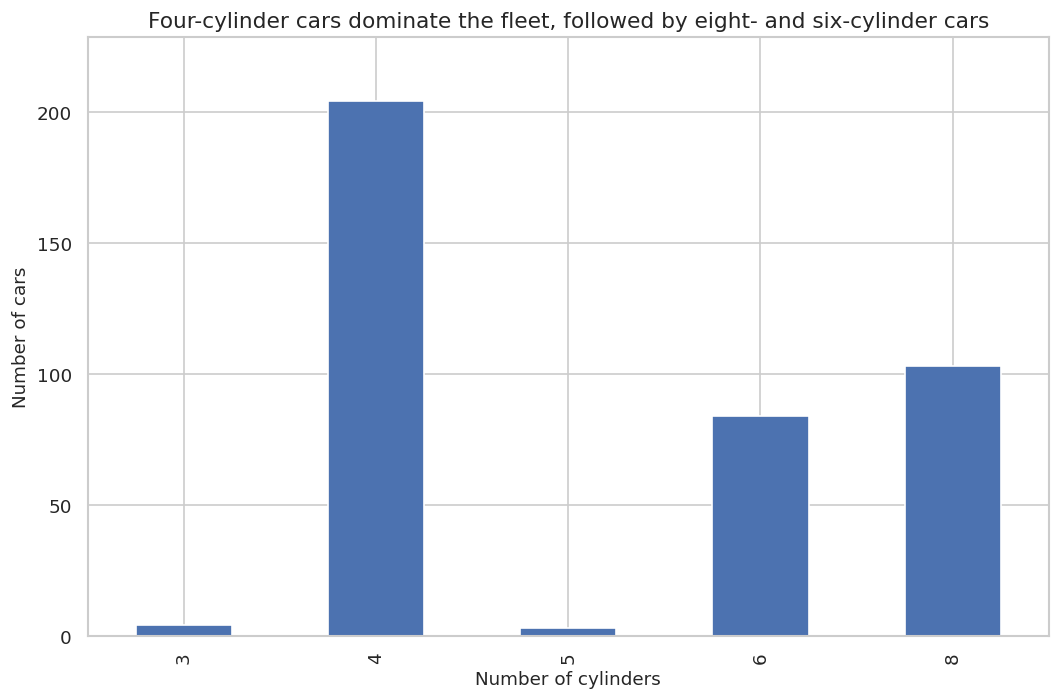

In [16]:
# Task 4.4 — Distribution of cylinders
cylinder_counts = mpg["cylinders"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 6))
cylinder_counts.plot(kind="bar", ax=ax)
ax.set_title("Four-cylinder cars dominate the fleet, followed by eight- and six-cylinder cars")
ax.set_xlabel("Number of cylinders")
ax.set_ylabel("Number of cars")
ax.set_ylim(0, cylinder_counts.max() * 1.12)
plt.tight_layout()
plt.show()


**Why this chart?** A bar chart is appropriate for counting discrete cylinder categories. The baseline is zero so the bar heights represent the counts honestly.

**Finding:** four-cylinder cars are by far the most common, followed by eight-cylinder and six-cylinder cars. Three- and five-cylinder cars are rare.

**Rows excluded:** none.


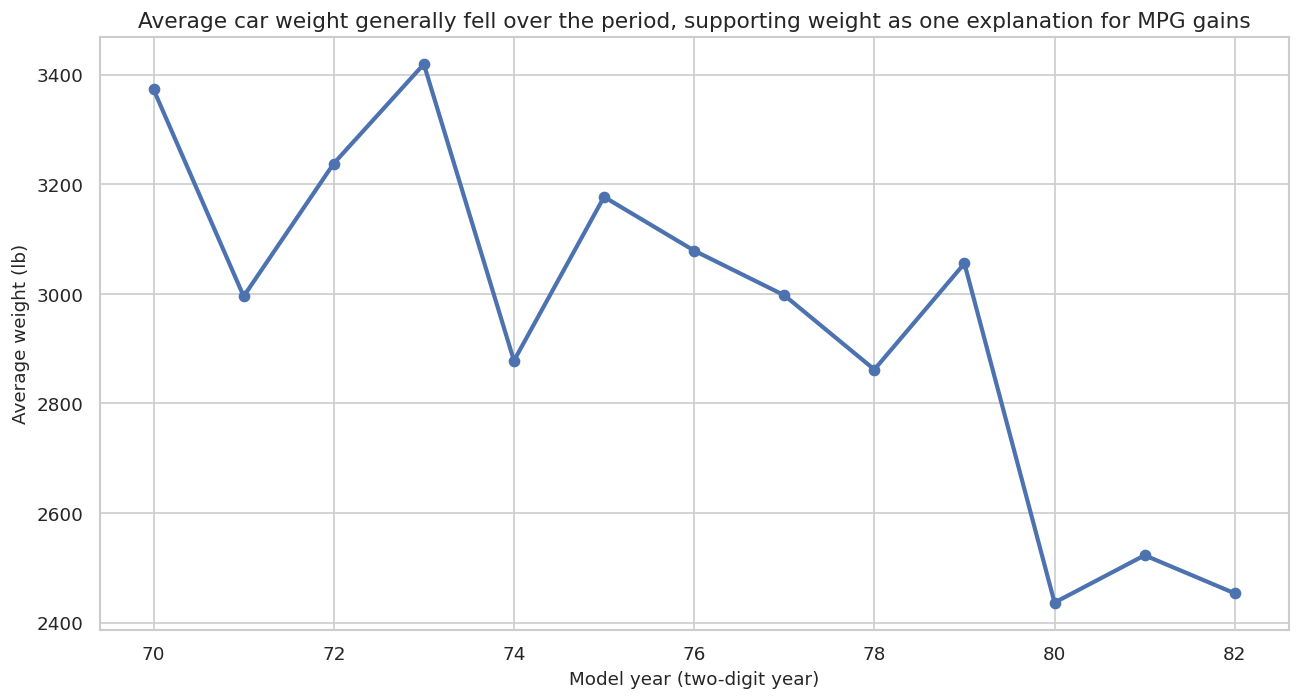

In [17]:
# Task 4.5 — Did cars also become lighter?
year_weight = mpg.groupby("model_year", as_index=False)["weight"].mean()

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(year_weight["model_year"], year_weight["weight"], marker="o", linewidth=2.5)
ax.set_title("Average car weight generally fell over the period, supporting weight as one explanation for MPG gains")
ax.set_xlabel("Model year (two-digit year)")
ax.set_ylabel("Average weight (lb)")
plt.tight_layout()
plt.show()


**Why this chart?** A line chart is suitable because the question asks whether weight changed over the same ordered time period as MPG.

**Finding:** average vehicle weight generally decreased, especially toward the late 1970s and early 1980s. Combined with the strong negative weight–MPG relationship, this supports the idea that lighter cars contributed to the improvement in fuel efficiency. It does not prove that weight was the only cause.

**Rows excluded:** none.


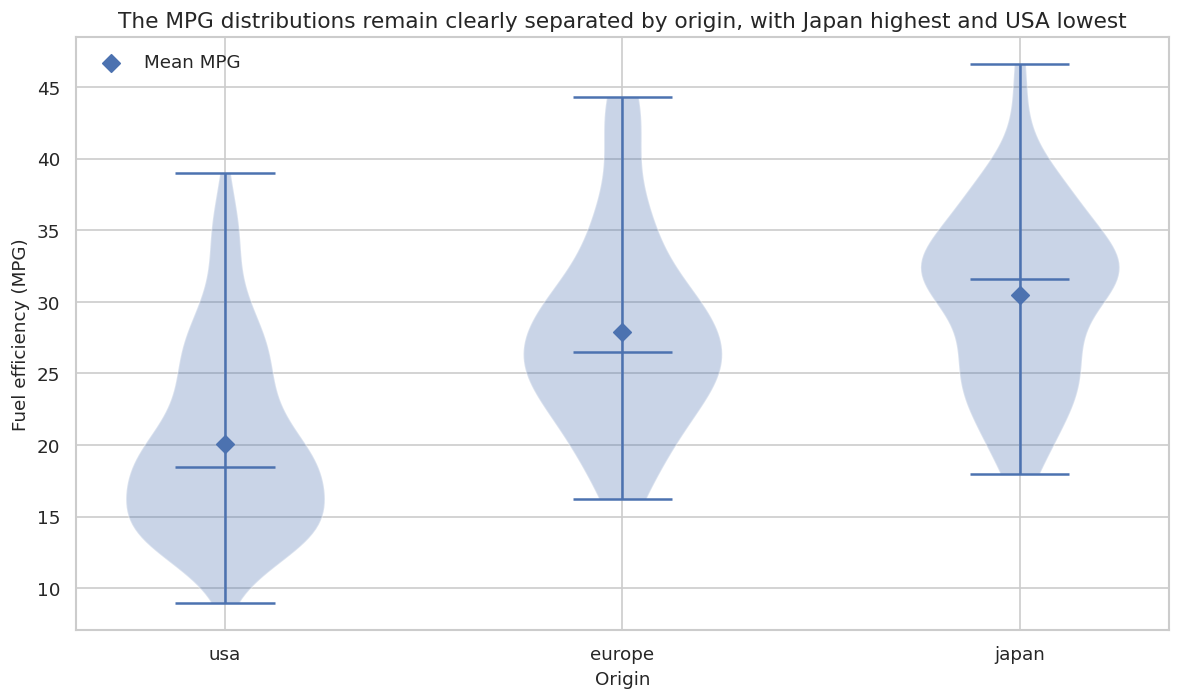

In [18]:
# Task 4.6 — Redraw the weakest chart: origin comparison
origin_order = ["usa", "europe", "japan"]
groups = [mpg.loc[mpg["origin"] == o, "mpg"].values for o in origin_order]

fig, ax = plt.subplots(figsize=(10, 6))
parts = ax.violinplot(groups, positions=np.arange(1, 4), showmeans=False, showmedians=True, showextrema=True)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(origin_order)

origin_means = mpg.groupby("origin")["mpg"].mean().reindex(origin_order)
ax.scatter([1, 2, 3], origin_means.values, marker="D", s=55, zorder=5, label="Mean MPG")

ax.set_title("The MPG distributions remain clearly separated by origin, with Japan highest and USA lowest")
ax.set_xlabel("Origin")
ax.set_ylabel("Fuel efficiency (MPG)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


**What I changed:** I redrew the origin comparison as a violin plot with an inner box and a mean marker. The original boxplot already answered the question well, but this version shows more of the distribution shape while still making the central spread and mean easy to compare.

**Rows excluded:** none.


## Task 5 — A real time series

The flights data contain 144 monthly observations from 1949 to 1960. The month names must first be converted into an ordered month number so that a real date can be created.


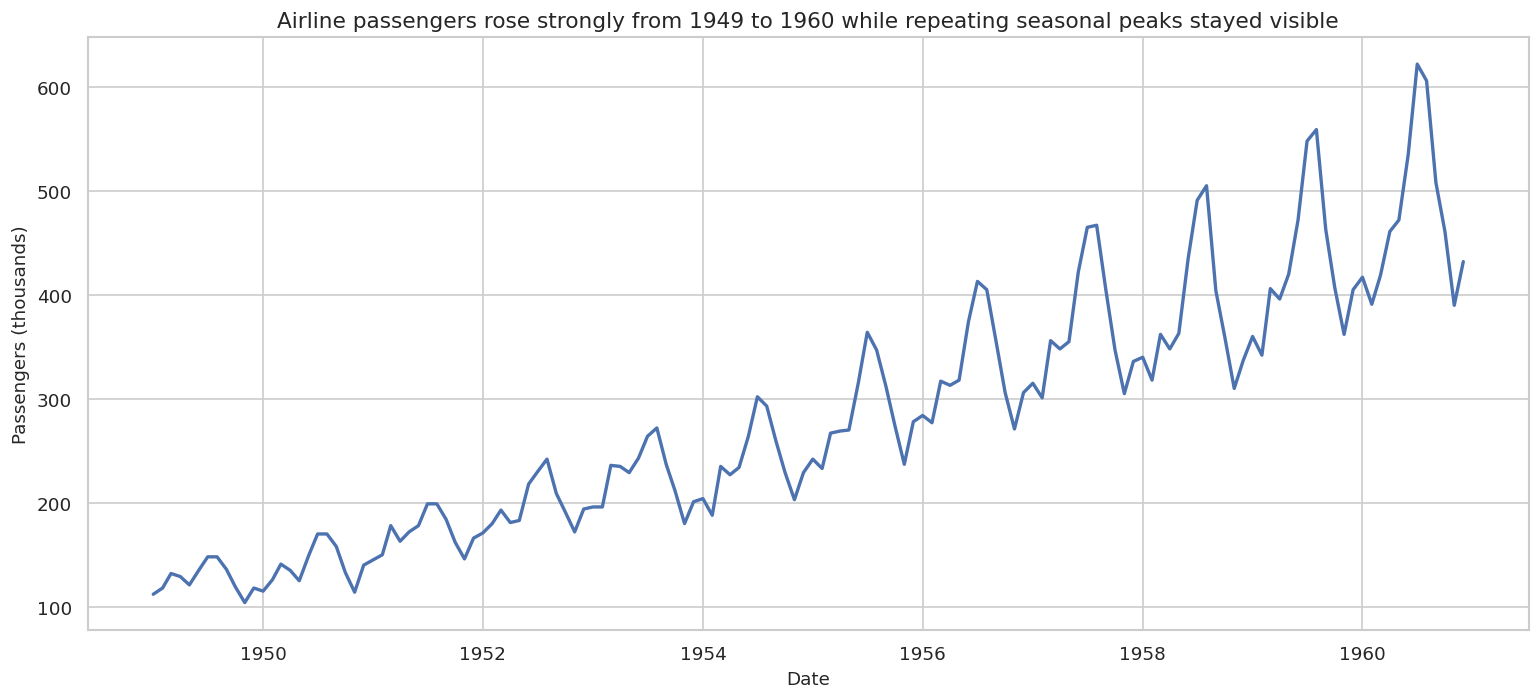

In [19]:
# Task 5.1 — Build a true monthly time axis
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

flights_ts = flights.copy()
flights_ts["month_num"] = pd.Categorical(
    flights_ts["month"],
    categories=month_order,
    ordered=True
).codes + 1

flights_ts["date"] = pd.to_datetime(
    dict(
        year=flights_ts["year"],
        month=flights_ts["month_num"],
        day=1,
    )
)

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(flights_ts["date"], flights_ts["passengers"], linewidth=2)
ax.set_title("Airline passengers rose strongly from 1949 to 1960 while repeating seasonal peaks stayed visible")
ax.set_xlabel("Date")
ax.set_ylabel("Passengers (thousands)")
plt.tight_layout()
plt.show()


**Why this chart?** A line chart is the standard choice for a continuous monthly time series. Combining year and month into a real date preserves the correct order and makes the long-term trend visible.

**Finding:** passenger totals rose strongly from 1949 to 1960, while a repeating within-year cycle is visible at the same time.

**Rows excluded:** none; all 144 monthly observations are plotted.


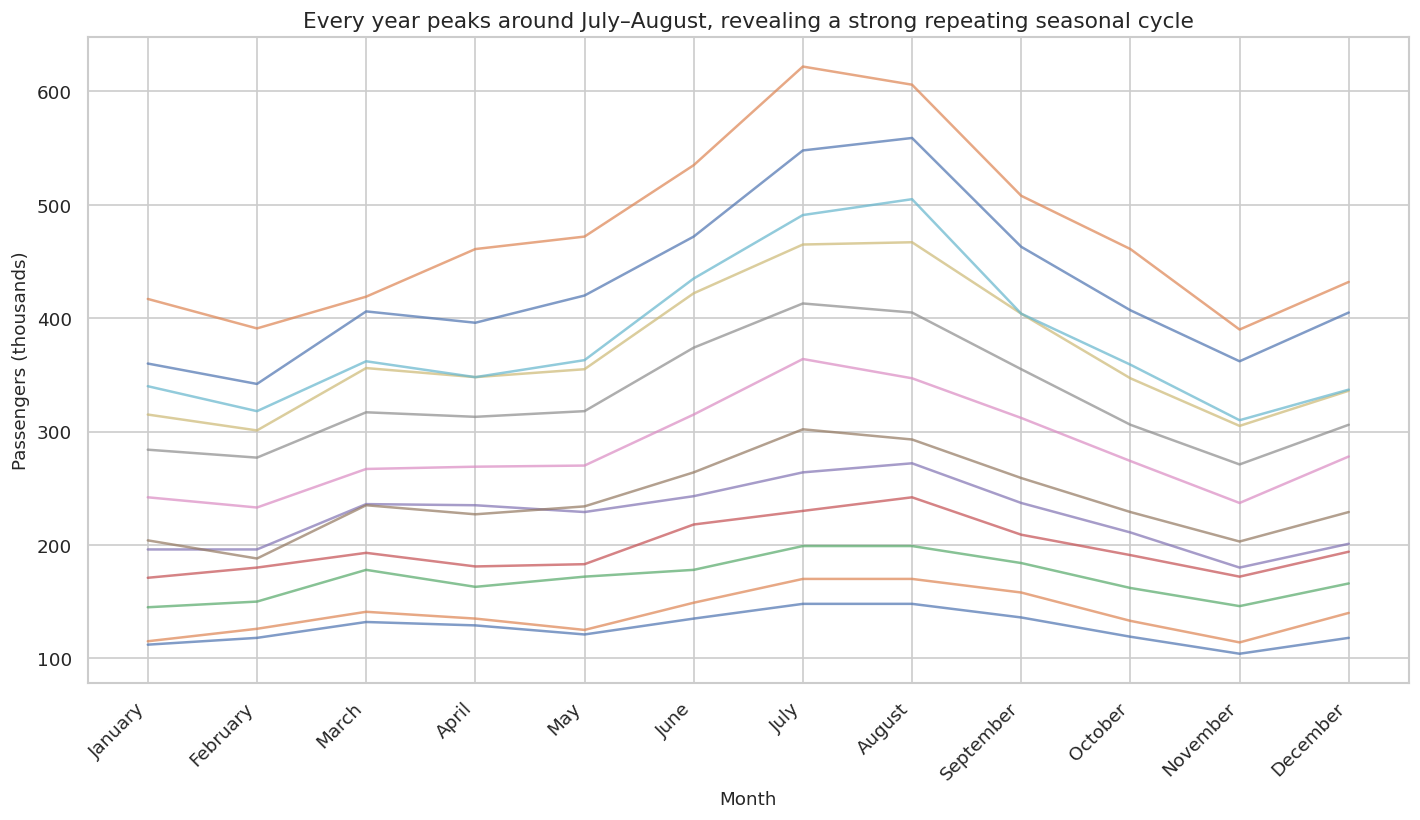

In [20]:
# Task 5.2 — Isolate the seasonal cycle
fig, ax = plt.subplots(figsize=(12, 7))

for year, group in flights_ts.groupby("year"):
    group = group.sort_values("month_num")
    ax.plot(
        group["month_num"],
        group["passengers"],
        linewidth=1.5,
        alpha=0.7,
    )

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_order, rotation=45, ha="right")
ax.set_title("Every year peaks around July–August, revealing a strong repeating seasonal cycle")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers (thousands)")
plt.tight_layout()
plt.show()


**Why this chart?** Putting each year on the same January-to-December axis removes the long-term growth trend from the x-axis and makes the within-year pattern directly comparable.

**Finding:** the same seasonal shape repeats every year, with the highest passenger counts generally occurring in July and August.

**Rows excluded:** none.


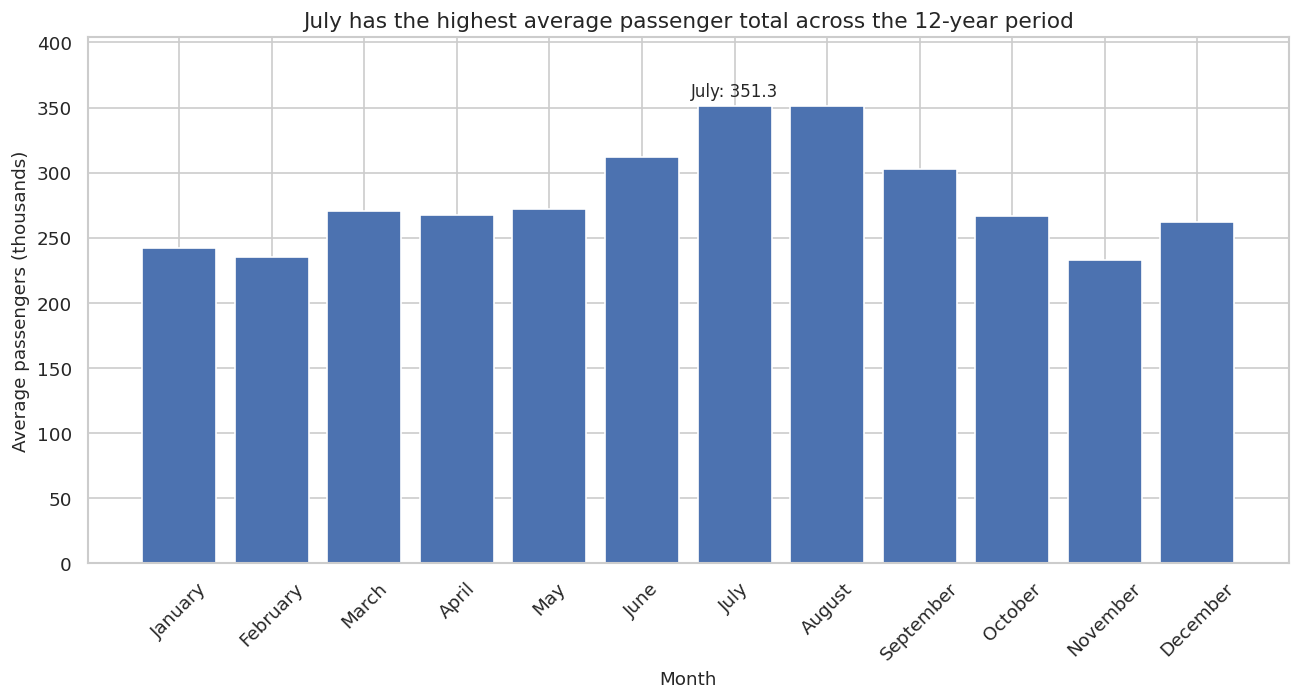

In [21]:
# Task 5.3 — Which month is consistently busiest?
monthly_mean = (
    flights_ts.groupby(["month_num", "month"], as_index=False)["passengers"]
    .mean()
    .sort_values("month_num")
)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(
    monthly_mean["month"],
    monthly_mean["passengers"],
)
ax.set_title("July has the highest average passenger total across the 12-year period")
ax.set_xlabel("Month")
ax.set_ylabel("Average passengers (thousands)")
ax.set_ylim(0, monthly_mean["passengers"].max() * 1.15)
ax.tick_params(axis="x", rotation=45)

# Label only the highest month to avoid clutter.
july_idx = monthly_mean["passengers"].idxmax()
july_position = monthly_mean.index.get_loc(july_idx)
july_value = monthly_mean.loc[july_idx, "passengers"]
ax.text(
    july_position,
    july_value + 4,
    f"July: {july_value:.1f}",
    ha="center",
    va="bottom",
    fontsize=10,
)

plt.tight_layout()
plt.show()


**Why this chart?** A bar chart makes a single categorical comparison—average passengers by month—immediately readable. The bars start at zero, as required.

**Finding:** July is the consistently busiest month on average, with about 351 thousand passengers, narrowly ahead of August.

**Rows excluded:** none.


### Final seasonal question

The seasonal swing gets larger in absolute passenger counts as the airline grows, so that alone does not prove that the strength of seasonality is increasing.

A good chart to settle the question would normalize each month's passenger count by that year's average (or divide each month by its annual mean). Plotting this **seasonal index** by month for every year would separate proportional seasonality from overall growth. If the normalized July/August peaks stay at similar heights over time, the larger raw swing is mainly a consequence of the airline carrying more passengers overall.

### Which chart belongs in a report?

I would use the **single time-series chart** as the main report figure because it communicates both the long-term growth and the repeating seasonal pattern in one view. The seasonal-cycle chart is useful as a supporting diagnostic when the seasonal pattern needs more detail. The busiest-month bar chart is more of a compact summary and would be redundant beside the first two unless the report specifically needs a ranking of months.

**Overall note:** no rows were excluded from the flights analysis.


## Final submission checklist

- All five tasks from `TASKS.md` are covered sequentially.
- Every chart title states a finding rather than merely repeating axis names.
- Bar charts use a zero baseline.
- No dual y-axes are used.
- Colour is used to distinguish meaningful groups rather than decorate every point.
- Labels are selective to avoid clutter.
- Missing-value decisions are stated directly on the relevant charts.
- No rows or outliers were silently removed.
- Each chart is followed immediately by a human-readable explanation of why the chart type was chosen and what it shows.
